# Módulo 15 — Simulação e precificação no modelo BCC97

## Introdução

Com o modelo BCC97 calibrado, opções europeias podem ser precificadas por Fourier. Para contratos sem fórmula, como opções americanas ou contratos que dependem da trajetória, é preciso **simular** o modelo completo: preço do ativo, variância estocástica, juros estocásticos e saltos, com as correlações corretas entre os choques.

Cada bloco traz cuidados próprios. A variância e os juros não podem ficar negativos; os saltos precisam de um termo de compensação para que o preço descontado continue sendo um martingal; e a ordem em que as variáveis são atualizadas em cada passo importa, porque usar informação do fim do passo para calcular o seu início introduz um viés que não desaparece com passos menores.

O capítulo constrói o simulador, confere seus preços europeus contra a fórmula de Fourier e o usa, com o algoritmo LSM do Capítulo 9, para precificar opções americanas no modelo geral.

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** capítulo 12 do livro.

## O que você vai conseguir fazer ao final

1. Discretizar o BCC97 completo: juros CIR, variância de Heston e índice com saltos.
2. Simular os saltos de Merton de forma exata e conferir a simulação pelo teste da martingal.
3. Reproduzir o viés de Monte Carlo da §12.3.1 do livro e identificar sua causa real.
4. Conferir a distribuição simulada inteira pelos cumulantes da função característica.
5. Calcular o prêmio de exercício antecipado de puts americanas com LSM e variável de controle.

## Onde estamos

O capítulo 12 é o ponto em que as peças se juntam: o modelo do Módulo 11, os esquemas do Módulo 12 e os parâmetros calibrados dos Módulos 13 e 14. O livro diz que o capítulo "apenas cola" as peças. Mas é na colagem que aparecem os problemas: um compensador esquecido, uma variância lida no instante errado. Com parâmetros extremos, os dois produzem vieses de dezenas de pontos.

Usamos dois conjuntos de parâmetros: o **Bates sintético** dos Módulos 13 e 14 (saltos relevantes) e os **parâmetros calibrados publicados pelo livro** na §11.4.5 (correlação quase −1 e volatilidade da variância perto de 1), que permitem reproduzir as tabelas do capítulo.

## 0. Preparação

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.interpolate as sci
from scipy.integrate import simpson
from scipy.optimize import brentq, brute, fmin, linprog
from scipy.stats import norm
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - sig * np.sqrt(T))


def vega_bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * norm.pdf(d1) * np.sqrt(T)


def vol_impl(preco, S, K, T, r):
    piso = max(S - K * np.exp(-r * T), 0.0)
    if not (piso + 1e-12 < preco < S):
        return np.nan
    return brentq(lambda s: float(bsm(S, K, T, r, s)) - preco, 1e-4, 4.0)


def cf_heston(u, T, v0, kappa, theta, sigma, rho):
    """Função característica de ln(S_T/S_0) - rT no Heston, forma estável (Módulo 11)."""
    xi = kappa - rho * sigma * 1j * u
    d = np.sqrt(xi**2 + sigma**2 * (1j * u + u**2))
    g = (xi - d) / (xi + d)
    e = np.exp(-d * T)
    A = kappa * theta / sigma**2 * ((xi - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    B = (xi - d) / sigma**2 * (1 - e) / (1 - g * e)
    return np.exp(A + B * v0)


def cf_saltos(u, T, lam, mu, delta):
    """Parte de saltos de Merton, com o drift compensado (11.13)-(11.14)."""
    omega = -lam * (np.exp(mu + 0.5 * delta**2) - 1)
    return np.exp((1j * u * omega + lam * (np.exp(1j * u * mu - 0.5 * u**2 * delta**2) - 1)) * T)


U_FINO = np.linspace(0, 2000, 200_001)
U_CAL = np.linspace(0, 300, 3001)


def calls(S0, K, T, r, heston, saltos=None, u=U_CAL):
    """Calls europeias pela fórmula de Lewis (11.12), vetorizada em (K, T, r) do mesmo tamanho.
    heston = (v0, κ_v, θ_v, σ_v, ρ); saltos = (λ, μ_J, δ) ou None."""
    K, T, r = (np.atleast_1d(np.asarray(x, float)) for x in (K, T, r))
    k = np.log(S0 / K) + r * T
    phi = cf_heston(u[None, :] - 0.5j, T[:, None], *heston)
    if saltos is not None:
        phi = phi * cf_saltos(u[None, :] - 0.5j, T[:, None], *saltos)
    h = np.exp(1j * u[None, :] * k[:, None]) * phi
    integral = simpson(h.real / (u**2 + 0.25), x=u, axis=1)
    return S0 - np.sqrt(S0 * K) * np.exp(-0.5 * r * T) / np.pi * integral


def zcb_cir(r0, kappa, theta, sigma, T):
    """Zero-cupom no CIR, (11.7)-(11.9) com t = 0."""
    g = np.sqrt(kappa**2 + 2 * sigma**2)
    e = np.exp(g * T) - 1
    D = 2 * g + (kappa + g) * e
    return (2 * g * np.exp((kappa + g) * T / 2) / D) ** (2 * kappa * theta / sigma**2) * np.exp(-2 * e / D * r0)


def fator_ft(xh, kappa, theta, sigma, dt, z):
    """Um passo Full Truncation (Módulo 12): devolve (x truncado, x̃ auxiliar)."""
    p = np.maximum(xh, 0)
    xh = xh + kappa * (theta - p) * dt + sigma * np.sqrt(p * dt) * z
    return np.maximum(xh, 0), xh


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. O esquema de simulação do BCC97

**Livro: §12.2 (equações 12.1 a 12.3)**

### 1.1 As três equações discretizadas

Com $s = t - \Delta t$, o livro propõe:

$$r_t:\quad \tilde r_t = \tilde r_s + \kappa_r(\theta_r - \tilde r_s^+)\Delta t + \sigma_r\sqrt{\tilde r_s^+}\sqrt{\Delta t}\,z^3_t, \qquad r_t = \tilde r_t^+ \tag{12.3}$$

$$v_t:\quad \tilde v_t = \tilde v_s + \kappa_v(\theta_v - \tilde v_s^+)\Delta t + \sigma_v\sqrt{\tilde v_s^+}\sqrt{\Delta t}\,z^2_t, \qquad v_t = \tilde v_t^+ \tag{12.2}$$

Os dois são o Full Truncation do Módulo 12. Para o índice, o livro escreve

$$S_t = S_s\Big(e^{(\bar r_t - r_J - v_t/2)\Delta t + \sqrt{v_t}\sqrt{\Delta t}\,z^1_t} + \big(e^{\mu_J + \delta z^4_t} - 1\big)\,y_t\Big), \qquad \bar r_t = \frac{r_s + r_t}{2}, \tag{12.1}$$

com $y_t \sim \text{Poisson}(\lambda\Delta t)$ e $r_J = \lambda(e^{\mu_J + \delta^2/2} - 1)$, a correção de drift dos saltos.

### 1.2 O esquema exato para os saltos, passo a passo

Para o índice, aplicamos Itô a $\ln S$ como no Módulo 10, agora com $v$ e $r$ estocásticos. Num passo, a parte contínua é integrada por log-Euler, e a de saltos pode ser integrada **exatamente**.

**Passo 1.** Em $[s, t]$ chegam $N \sim \text{Poisson}(\lambda\Delta t)$ saltos, cada um multiplicando $S$ por $e^{J_i}$, com $J_i \sim N(\mu_J, \delta^2)$ independentes.

**Passo 2.** A soma dos log-saltos, dado $N$, é normal: $\sum_{i=1}^NJ_i \sim N(N\mu_J,\ N\delta^2)$. Basta um normal $z^4$ por passo: $\sum J_i = N\mu_J + \sqrt N\,\delta\,z^4$.

**Passo 3.** O passo completo é

$$\ln S_t = \ln S_s + \big(\bar r_t - r_J - \tfrac12v_s\big)\Delta t + \sqrt{v_s}\sqrt{\Delta t}\,z^1_t + N\mu_J + \sqrt N\,\delta\,z^4_t.$$

**Passo 4 (conferência).** Dado o passado, com $v_s$ conhecido e $r$ independente do resto,

$$\mathbb{E}\big[e^{N\mu_J + \sqrt N\delta z^4}\big] = \mathbb{E}\big[(e^{\mu_J + \delta^2/2})^N\big] = e^{\lambda\Delta t(e^{\mu_J + \delta^2/2} - 1)} = e^{r_J\Delta t},$$

que cancela exatamente o $-r_J\Delta t$. Com o $e^{-v_s\Delta t/2}$ cancelando a convexidade do choque browniano (Módulo 12), $S$ descontado por $\bar r$ é uma martingal passo a passo.

### 1.3 O que o código do livro faz de diferente

O script da §12.5.1 se afasta de (12.1) e do esquema exato em três pontos:

| | Esquema exato (acima) | Código da §12.5.1 |
|---|---|---|
| Variância no passo do índice | $v_s$ (início do passo) | `v[t]` (fim do passo), como no Módulo 12 |
| Compensador dos saltos | $-r_J\Delta t$ no expoente | `rj` é calculado e **nunca usado** |
| Saltos | multiplicativos, $e^{\sum J_i}$ | aditivos, $(e^{\mu_J + \delta z} - 1)\,y_t$, com um único tamanho para todos os $y_t$ saltos do passo |

Além disso, o script liga por padrão o moment matching com a correção de drift `bias`, que, como no Módulo 12, esconde parte desses efeitos.

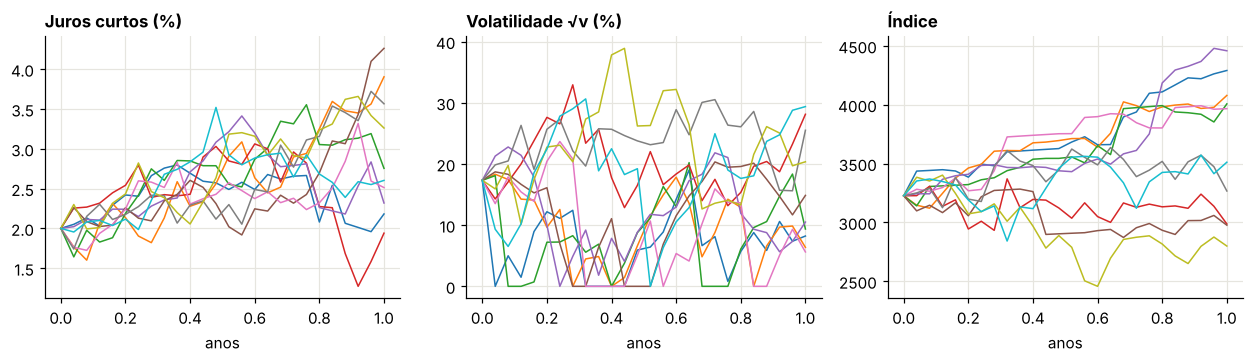

OK — Full Truncation: variância e juros nunca ficam negativos


In [2]:
S0 = 3225.93
CIR = dict(r0=0.02, kappa=0.5, theta=0.045, sigma=0.08)       # curva sintética dos Módulos 13 e 14
NOMES = ["κ_v", "θ_v", "σ_v", "ρ", "v0", "λ", "μ_J", "δ"]
BATES = np.array([3.0, 0.04, 0.5, -0.7, 0.03, 0.15, -0.15, 0.10])               # modelo verdadeiro dos Módulos 13 e 14
LIVRO = np.array([22.212, 0.025, 0.952, -0.999, 0.036, 0.008, -0.501, 0.000])   # BCC97 calibrado no livro (§11.4.5)


def simular_bcc(p, T, M0, I, rng, olhar_frente=False, compensador=True, aditivo=False,
                mm=False, trajetorias=False):
    """Simula o BCC97 com Full Truncation para r e v.
    Padrão = esquema exato da Seção 1.2. As opções reproduzem os desvios do código do livro:
      olhar_frente: usa v[t] no passo do índice; compensador=False: omite −r_J;
      aditivo: saltos aditivos de (12.1); mm: moment matching e correção 'bias'.
    Devolve S_T e o desconto exp(−∫r), ou as trajetórias completas (S, v, r)."""
    kappa, theta, sigma, rho, v0, lam, mu, delta = p
    M = max(int(round(M0 * T)), 1)
    dt = T / M
    Z = rng.standard_normal((4, M, I // 2))
    Z = np.concatenate([Z, -Z], axis=2)                       # antitéticas, como no livro
    if mm:
        Z = (Z - Z.mean(axis=(1, 2), keepdims=True)) / Z.std(axis=(1, 2), keepdims=True)
    N = rng.poisson(lam * dt, (M, I))
    rJ = lam * (np.exp(mu + 0.5 * delta**2) - 1)
    r = np.full(I, CIR["r0"]); rh = r.copy()
    v = np.full(I, v0); vh = v.copy()
    S = np.full(I, S0); int_r = np.zeros(I)
    if trajetorias:
        Sp, vp, rp = [S.copy()], [v.copy()], [r.copy()]
    for t in range(M):
        z1 = Z[1, t]
        z2 = rho * z1 + np.sqrt(1 - rho**2) * Z[2, t]
        r_novo, rh = fator_ft(rh, CIR["kappa"], CIR["theta"], CIR["sigma"], dt, Z[0, t])
        v_novo, vh = fator_ft(vh, kappa, theta, sigma, dt, z2)
        rbar = 0.5 * (r + r_novo)
        int_r += rbar * dt
        vu = v_novo if olhar_frente else v
        choque = np.sqrt(vu * dt) * z1
        if mm:
            choque = choque - choque.mean()
        deriva = (rbar - (rJ if compensador else 0.0) - 0.5 * vu) * dt
        if aditivo:
            S = S * (np.exp(deriva + choque) + (np.exp(mu + delta * Z[3, t]) - 1) * N[t])
        else:
            S = S * np.exp(deriva + choque + N[t] * mu + np.sqrt(N[t]) * delta * Z[3, t])
        r, v = r_novo, v_novo
        if trajetorias:
            Sp.append(S.copy()); vp.append(v.copy()); rp.append(r.copy())
    if trajetorias:
        return np.array(Sp), np.array(vp), np.array(rp)
    return S, np.exp(-int_r)


def calls_bcc(p, K, T):
    """Calls europeias pela fórmula de Lewis com r̄ = −ln B0(T)/T, como no livro."""
    kappa, theta, sigma, rho, v0, lam, mu, delta = p
    K = np.atleast_1d(np.asarray(K, float))
    rbar = -np.log(zcb_cir(T=T, **CIR)) / T
    return calls(S0, K, np.full(len(K), T), np.full(len(K), rbar), (v0, kappa, theta, sigma, rho), (lam, mu, delta), U_FINO)


rng = np.random.default_rng(100000)
Sp, vp, rp = simular_bcc(BATES, 1.0, 25, 10_000, rng, trajetorias=True)
fig, axs = plt.subplots(1, 3, figsize=(11.5, 3.4))
tt = np.linspace(0, 1, 26)
for i in range(10):
    axs[0].plot(tt, 100 * rp[:, i], lw=1)
    axs[1].plot(tt, 100 * np.sqrt(vp[:, i]), lw=1)
    axs[2].plot(tt, Sp[:, i], lw=1)
axs[0].set_title("Juros curtos (%)"); axs[1].set_title("Volatilidade √v (%)"); axs[2].set_title("Índice")
for ax in axs:
    ax.set_xlabel("anos")
plt.tight_layout(); plt.show()
ok(np.all(vp >= 0) and np.all(rp >= 0), "Full Truncation: variância e juros nunca ficam negativos")

As figuras correspondem às 12.1 a 12.3 do livro, para o modelo verdadeiro dos Módulos 13 e 14 (Bates com juros CIR), 25 passos em 1 ano. Os saltos aparecem como quedas verticais no índice.

---
## 2. O teste da martingal e os saltos

Como visto no Módulo 12, a conferência mais barata de uma simulação de preços é $\mathbb{E}\big[e^{-\int_0^Tr\,dt}S_T\big] = S_0$. Aqui também conferimos calls de 1 ano contra a fórmula de Lewis.

### Laboratório 1 — Separar os efeitos do código dos saltos

Usamos o modelo de Bates verdadeiro ($\lambda = 0{,}15$, $\mu_J = -0{,}15$), em que os saltos pesam. $r_J = 0{,}15\,(e^{-0{,}15 + 0{,}005} - 1) \approx -2{,}0\%$ ao ano. Variamos um defeito de cada vez, sem olhar para a frente, para isolar o efeito dos saltos.

In [3]:
T1, K1 = 1.0, np.array([3050.0, 3225.0, 3400.0])
ref1 = calls_bcc(BATES, K1, T1)
rJ_bates = BATES[5] * (np.exp(BATES[6] + 0.5 * BATES[7] ** 2) - 1)
print("r_J =", f3(100 * rJ_bates), "% ao ano | previsão do erro de E[e^{−∫r}S_T] sem compensador:",
      f3(S0 * (np.exp(rJ_bates * T1) - 1)))

variantes = [("esquema exato", dict()),
             ("sem compensador −r_J", dict(compensador=False)),
             ("saltos aditivos", dict(aditivo=True)),
             ("aditivos e sem compensador (como o livro)", dict(compensador=False, aditivo=True))]
rng = np.random.default_rng(1)
linhas = []
for nome, kw in variantes:
    ST, D = simular_bcc(BATES, T1, 50, 200_000, rng, **kw)
    mart = np.mean(D * ST) - S0
    ep = np.std(D * ST) / np.sqrt(len(ST))
    c = (D[:, None] * np.maximum(ST[:, None] - K1, 0)).mean(axis=0)
    linhas.append((nome, mart, ep, *(c - ref1)))
tab1 = pd.DataFrame(linhas, columns=["variante", "erro de E[e^{−∫r}S_T]", "erro-padrão",
                                     "erro call 3.050", "erro call 3.225", "erro call 3.400"])
tabela(tab1)

t1 = tab1.set_index("variante")
ok(abs(t1.loc["esquema exato", "erro de E[e^{−∫r}S_T]"]) < 3 * t1.loc["esquema exato", "erro-padrão"] + 0.5,
   "o esquema exato passa no teste da martingal")
prev = S0 * (np.exp(rJ_bates * T1) - 1)
obs = t1.loc["sem compensador −r_J", "erro de E[e^{−∫r}S_T]"]
ok(abs(obs / prev - 1) < 0.1, "sem o compensador, o erro é o previsto, S0·(e^{r_J T} − 1), a menos de 10%")
ok(abs(t1.loc["saltos aditivos", "erro de E[e^{−∫r}S_T]"]) < 0.15 * abs(prev),
   "os saltos aditivos, sozinhos, quase não afetam a média")
ok(t1.loc["aditivos e sem compensador (como o livro)", "erro call 3.225"] < -30,
   "no código do livro, a call de 1 ano no dinheiro sai mais de 30 pontos abaixo da fórmula")

r_J = -2,025 % ao ano | previsão do erro de E[e^{−∫r}S_T] sem compensador: -64,658


,variante,erro de E[e^{−∫r}S_T],erro-padrão,erro call 3.050,erro call 3.225,erro call 3.400
0,esquema exato,"0,011","1,379","0,188","0,138","0,075"
1,sem compensador −r_J,"-64,756","1,349","-48,152","-41,917","-34,536"
2,saltos aditivos,"0,294","1,378","0,449","0,388","0,257"
3,aditivos e sem compensador (como o livro),"-65,211","1,355","-47,141","-40,945","-33,663"


OK — o esquema exato passa no teste da martingal
OK — sem o compensador, o erro é o previsto, S0·(e^{r_J T} − 1), a menos de 10%
OK — os saltos aditivos, sozinhos, quase não afetam a média
OK — no código do livro, a call de 1 ano no dinheiro sai mais de 30 pontos abaixo da fórmula


**O que aprendemos.** O defeito que pesa é o **compensador ausente**: a variável `rj` é calculada no script e nunca entra na conta. Sem o $-r_J\Delta t$ (que, com $r_J < 0$, somaria 2% ao ano), o índice descontado cai em média como $e^{r_JT}$: perde $|r_J| \approx 2\%$ ao ano, exatamente o previsto. Os saltos aditivos, embora não sejam o modelo (um único tamanho de salto vale para todos os saltos do passo, e o fator não é exponencial), quase não mudam a média com $\lambda\Delta t$ pequeno.

Com os parâmetros calibrados do livro ($\lambda = 0{,}008$, $\mu_J = -0{,}501$), $r_J \approx -0{,}3\%$ ao ano: o defeito existe, mas é pequeno. O viés grande que o livro mostra na §12.3.1 vem de outro lugar.

---
## 3. O viés da Seção 12.3.1

**Livro: §12.3.1 e §12.5.2**

O livro compara Monte Carlo e Fourier para calls europeias e relata desvios **enormes**: com 50 passos por ano, o Monte Carlo fica 22 a 28 pontos acima da fórmula em 1 ano, e 45 a 52 pontos acima em 3 anos. Com 200 passos por ano o desvio cai, mas não some. O livro conclui que esquemas de Euler exigem muitos passos em modelos complexos.

Os parâmetros calibrados do livro são extremos: $\sigma_v = 0{,}952$, $\kappa_v = 22{,}2$ e, sobretudo, $\rho = -0{,}999$. Com $\rho \approx -1$, o viés de olhar para a frente do Módulo 12 vale $\tfrac12\rho\sigma_v \approx -0{,}475$ por ano no drift de $\ln S$. A correção `bias` do moment matching remove a média desse drift espúrio, mas não os efeitos de segunda ordem, que dependem de $\Delta t$.

### Laboratório 2 — Reproduzir a tabela do livro e encontrar a causa

Usamos os parâmetros publicados do livro (§11.4.5) com a nossa curva CIR, os vencimentos e strikes da §12.3.1, 50.000 trajetórias, e três versões do simulador:

* **exato**: o esquema da Seção 1.2;
* **livro**: `v[t]`, sem compensador, saltos aditivos, moment matching ligado (o padrão do script);
* **livro sem moment matching**: o mesmo, com `mm` desligado.

In [4]:
PRAZOS2 = [1 / 12, 0.5, 1.0, 3.0]
K2 = np.array([3050.0, 3225.0, 3400.0])
LIVRO_CFG = dict(olhar_frente=True, compensador=False, aditivo=True, mm=True)
rng = np.random.default_rng(2)
t0 = time.time()
linhas = []
for T in PRAZOS2:
    ref = calls_bcc(LIVRO, K2, T)
    for M0 in (50, 200):
        for nome, kw in [("exato", dict()), ("livro", LIVRO_CFG),
                         ("livro sem moment matching", dict(LIVRO_CFG, mm=False))]:
            ST, D = simular_bcc(LIVRO, T, M0, 50_000, rng, **kw)
            pay = D[:, None] * np.maximum(ST[:, None] - K2, 0)
            c = pay.mean(axis=0)
            ep = (pay[: len(ST) // 2] + pay[len(ST) // 2:]).std(axis=0) / 2 / np.sqrt(len(ST) // 2)   # pares antitéticos
            for K, ci, fi, ei in zip(K2, c, ref, ep):
                linhas.append((T, M0, nome, K, fi, ci - fi, ei))
tab2 = pd.DataFrame(linhas, columns=["T", "passos por ano", "simulador", "K", "Fourier", "MC − Fourier", "erro-padrão"])
print(f"tempo: {time.time() - t0:.1f} s")
piv = tab2.pivot_table(index=["T", "K"], columns=["simulador", "passos por ano"], values="MC − Fourier")
tabela(piv[["exato", "livro"]])

tempo: 54.6 s


simulador         exato          livro        
passos por ano      50     200     50      200
T        K                                    
0.083333 3050.0   0,633  0,148   2,071  -0,351
         3225.0   2,314  0,191   2,490  -0,588
         3400.0   1,192  0,090   0,672   0,625
0.500000 3050.0  -1,477  0,409  14,763   0,853
         3225.0  -1,369  0,298  18,808   3,039
         3400.0  -0,807  0,097  20,045   4,751
1.000000 3050.0  -0,517  1,806  21,510   0,247
         3225.0  -0,238  1,746  25,559   2,429
         3400.0  -0,305  1,433  27,690   4,216
3.000000 3050.0   1,683  4,405  32,921  -2,395
         3225.0   1,687  4,675  37,502   0,658
         3400.0   1,707  4,837  41,043   3,410

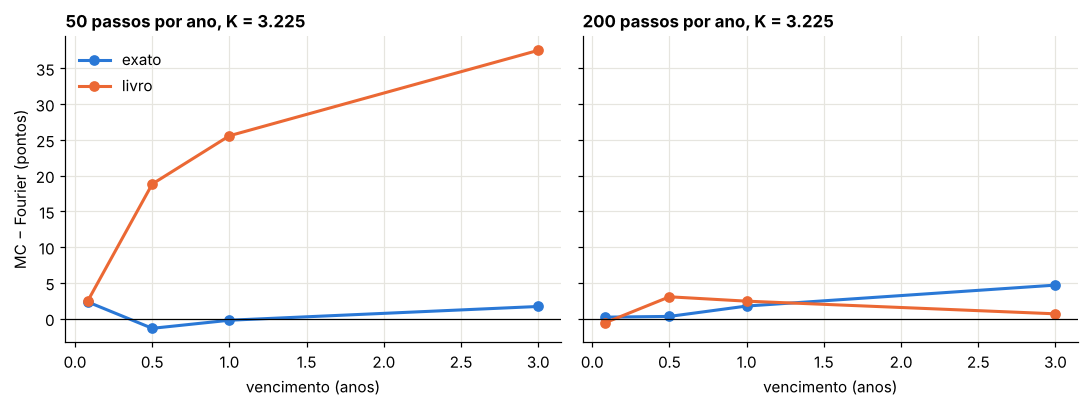

livro sem moment matching, T = 1, 50 passos — MC − Fourier: ['-358,571', '-249,357', '-160,905']
esquema exato: maior |erro|/erro-padrão = 19,257 | erro-padrão em 3 anos ≈ 2,204
OK — a partir de 6 meses, o esquema exato fica dentro de 4 erros-padrão, já com 50 passos por ano
OK — em 1 mês (só 4 passos com 50 por ano) há um viés de Euler real, que some com 200 passos por ano
OK — o simulador do livro reproduz o viés da §12.3.1: 15 a 35 pontos acima em 1 ano
OK — com 200 passos por ano o viés do livro cai, mas continua acima do esquema exato
OK — sem o moment matching, o código do livro erra por centenas de pontos


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, M0 in zip(axs, (50, 200)):
    for nome, cor in [("exato", AZUL), ("livro", LARANJA)]:
        d = tab2[(tab2["passos por ano"] == M0) & (tab2["simulador"] == nome) & (tab2["K"] == 3225.0)]
        ax.plot(d["T"], d["MC − Fourier"], "o-", color=cor, label=nome)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{M0} passos por ano, K = 3.225"); ax.set_xlabel("vencimento (anos)")
axs[0].set_ylabel("MC − Fourier (pontos)"); axs[0].legend()
plt.tight_layout(); plt.show()

sem_mm = tab2[(tab2["simulador"] == "livro sem moment matching") & (tab2["T"] == 1.0) & (tab2["passos por ano"] == 50)]
print("livro sem moment matching, T = 1, 50 passos — MC − Fourier:", [f3(x) for x in sem_mm["MC − Fourier"]])

ex = tab2[tab2["simulador"] == "exato"]
lv = tab2[tab2["simulador"] == "livro"]
z_ex = (ex["MC − Fourier"] / ex["erro-padrão"]).abs()
print("esquema exato: maior |erro|/erro-padrão =", f3(z_ex.max()), "| erro-padrão em 3 anos ≈", f3(ex[ex["T"] == 3.0]["erro-padrão"].mean()))
longos = ex["T"] >= 0.5
ok(z_ex[longos].max() < 4, "a partir de 6 meses, o esquema exato fica dentro de 4 erros-padrão, já com 50 passos por ano")
curto = ex[ex["T"] < 0.1]
ok(curto[curto["passos por ano"] == 200]["MC − Fourier"].abs().max() < 0.5 < curto[curto["passos por ano"] == 50]["MC − Fourier"].abs().max(),
   "em 1 mês (só 4 passos com 50 por ano) há um viés de Euler real, que some com 200 passos por ano")
d1 = lv[(lv["T"] == 1.0) & (lv["passos por ano"] == 50)]["MC − Fourier"]
ok(d1.between(15, 35).all(), "o simulador do livro reproduz o viés da §12.3.1: 15 a 35 pontos acima em 1 ano")
d3_50 = lv[(lv["T"] == 3.0) & (lv["passos por ano"] == 50)]["MC − Fourier"].abs().mean()
d3_200 = lv[(lv["T"] == 3.0) & (lv["passos por ano"] == 200)]["MC − Fourier"].abs().mean()
ok(d3_200 < d3_50 / 2, "com 200 passos por ano o viés do livro cai, mas continua acima do esquema exato")
ok((sem_mm["MC − Fourier"] < -100).all(), "sem o moment matching, o código do livro erra por centenas de pontos")

**O que aprendemos.**

* O simulador do livro reproduz a tabela da §12.3.1 com boa precisão: o viés não é ruído, é sistemático e cresce com o vencimento.
* O esquema exato, **com os mesmos 50 passos por ano**, acerta dentro do ruído estatístico a partir de 6 meses (o erro-padrão de uma call de 3 anos com 50.000 trajetórias é de cerca de 2 pontos). No vencimento de 1 mês, 50 passos por ano são só 4 passos, e aparece um viés de Euler real de 1 a 2 pontos, que some com 200 passos. Ele é do mesmo tamanho nos dois simuladores: essa parte da tabela do livro é, de fato, discretização. A conclusão do livro ("esquemas de Euler exigem muitos passos") não se sustenta: o problema é o `v[t]`, não o Euler.
* Sem o moment matching, o código do livro erra por centenas de pontos: é o drift espúrio $\tfrac12\rho\sigma_v$ com $\rho \approx -1$. A correção `bias` esconde a maior parte do erro, e o que sobra (de segunda ordem, por isso dependente de $\Delta t$) é o que o livro viu e atribuiu ao Euler.

---
## 4. A distribuição do índice

**Livro: §12.2 (Figura 12.4)**

O livro observa que os saltos afastam a distribuição de $S_T$ da lognormal. Podemos medir isso com precisão: os **cumulantes** de $X = \ln(S_T/S_0)$ saem da função característica, $\kappa_n = i^{-n}\,\frac{d^n}{du^n}\ln\varphi(u)\big|_{u=0}$. A assimetria é $\kappa_3/\kappa_2^{3/2}$ e o excesso de curtose é $\kappa_4/\kappa_2^2$; ambos são zero na normal.

### Laboratório 3 — Assimetria e curtose: simulação contra a função característica

Para juros constantes ($\bar r$ da curva) a função característica do BCC97 é o produto Heston × saltos (11.16). Derivamos $\ln\varphi$ numericamente por diferenças finitas em $u = 0$.

,momento,função característica,simulação
0,desvio-padrão de ln S_T,"0,211","0,211"
1,assimetria,"-1,194","-1,185"
2,excesso de curtose,"2,609","2,587"


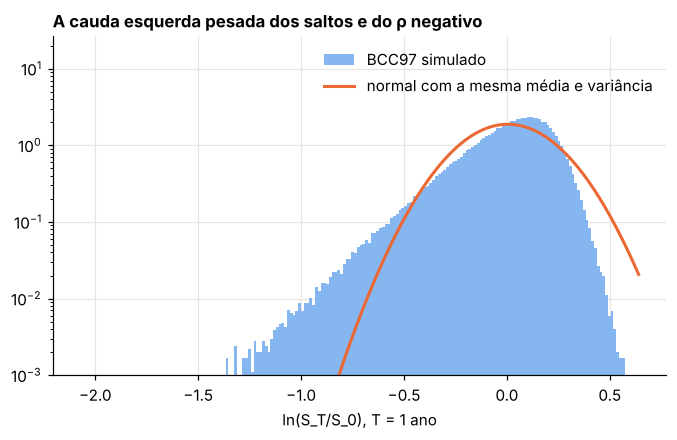

OK — o desvio-padrão simulado confere com o da função característica a menos de 1%
OK — a assimetria simulada confere com a da função característica
OK — o excesso de curtose simulado confere com o da função característica
OK — a distribuição é bem assimétrica à esquerda e de cauda pesada


In [6]:
T3 = 1.0
rbar3 = -np.log(zcb_cir(T=T3, **CIR)) / T3


def log_cf(u):
    kappa, theta, sigma, rho, v0, lam, mu, delta = BATES
    return np.log(cf_heston(u, T3, v0, kappa, theta, sigma, rho) * cf_saltos(u, T3, lam, mu, delta)) + 1j * u * rbar3 * T3


h = 0.02
us = h * np.arange(-3, 4)
L = np.array([log_cf(u) for u in us])
d2 = (L[2] - 2 * L[3] + L[4]) / h**2
d3 = (L[5] - 2 * L[4] + 2 * L[2] - L[1]) / (2 * h**3)
d4 = (L[5] - 4 * L[4] + 6 * L[3] - 4 * L[2] + L[1]) / h**4
k2, k3, k4 = (-d2).real, (1j * d3).real, d4.real
assim_cf, curt_cf = k3 / k2**1.5, k4 / k2**2

rng = np.random.default_rng(3)
ST, D = simular_bcc(BATES, T3, 50, 400_000, rng)
X = np.log(ST / S0)
c = X - X.mean()
assim_mc = np.mean(c**3) / np.mean(c**2) ** 1.5
curt_mc = np.mean(c**4) / np.mean(c**2) ** 2 - 3
tab3 = pd.DataFrame({"momento": ["desvio-padrão de ln S_T", "assimetria", "excesso de curtose"],
                     "função característica": [np.sqrt(k2), assim_cf, curt_cf],
                     "simulação": [c.std(), assim_mc, curt_mc]})
tabela(tab3)

fig, ax = plt.subplots()
ax.hist(X, bins=200, density=True, color=RAMPA[0], label="BCC97 simulado")
gx = np.linspace(X.min(), X.max(), 400)
ax.plot(gx, norm.pdf(gx, X.mean(), X.std()), color=LARANJA, label="normal com a mesma média e variância")
ax.set_yscale("log"); ax.set_ylim(1e-3, None)
ax.set_xlabel("ln(S_T/S_0), T = 1 ano"); ax.set_title("A cauda esquerda pesada dos saltos e do ρ negativo")
ax.legend(); plt.show()

ok(abs(np.sqrt(k2) / c.std() - 1) < 0.01, "o desvio-padrão simulado confere com o da função característica a menos de 1%")
ok(abs(assim_mc - assim_cf) < 0.05, "a assimetria simulada confere com a da função característica")
ok(abs(curt_mc - curt_cf) < 0.3, "o excesso de curtose simulado confere com o da função característica")
ok(assim_cf < -0.5 and curt_cf > 1, "a distribuição é bem assimétrica à esquerda e de cauda pesada")

Em escala logarítmica, a diferença para a normal fica nítida: a cauda esquerda do modelo é muito mais grossa. É ela que dá o skew das volatilidades implícitas (Módulo 2).

---
## 5. Puts americanas no BCC97

**Livro: §12.3.2 e §12.5.3**

### 5.1 O que o livro calcula

O livro aplica o LSM com 11 funções de base (como no Módulo 12) às trajetórias do seu simulador e reporta a diferença entre a put americana (LSM) e a europeia (Fourier) como **prêmio de exercício antecipado**. Dois problemas:

1. As trajetórias carregam o viés da Seção 3. A diferença mistura prêmio e viés.
2. O título da §12.5.3 fala de "American Call Options", mas o script avalia puts. É bom lembrar que, **sem dividendos**, uma call americana não deve ser exercida antes (Módulo 9): o prêmio da call é zero.

### 5.2 A forma limpa: LSM com controle

Seguimos o Módulo 12: trajetórias do esquema exato, LSM com as 11 funções de base, e a put europeia simulada nas mesmas trajetórias como variável de controle, com o $\lambda^*$ estimado. O prêmio passa a ser **americana com controle − europeia de Fourier**, e o viés comum (se houver) se cancela.

### Laboratório 4 — Prêmio de exercício antecipado

In [7]:
def lsm(S, v, r, K, T, tipo="put"):
    """LSM com as 11 funções de base do livro. Devolve os fluxos descontados até 0 e o payoff europeu descontado."""
    M = S.shape[0] - 1
    dt = T / M
    h = np.maximum(K - S, 0) if tipo == "put" else np.maximum(S - K, 0)
    fd = np.exp(-(r[1:] + r[:-1]) / 2 * dt)
    V = h[-1].copy()
    for t in range(M - 1, 0, -1):
        V = V * fd[t]
        itm = h[t] > 0
        if itm.sum() > 20:
            s_, v_, r_ = S[t, itm] / S0, v[t, itm], r[t, itm]
            X = np.column_stack([np.ones_like(s_), r_, v_, s_, r_**2, v_**2, s_**2,
                                 v_ * r_, s_ * r_, s_ * v_, s_ * v_ * r_])
            cont = X @ np.linalg.lstsq(X, V[itm], rcond=None)[0]
            idx = np.where(itm)[0][h[t, itm] > cont]
            V[idx] = h[t, idx]
    return V * fd[0], np.prod(fd, axis=0) * h[-1]


PRAZOS4 = [1 / 12, 0.5, 1.0, 2.0]
rng = np.random.default_rng(4)
t0 = time.time()
linhas = []
for T in PRAZOS4:
    Sp, vp, rp = simular_bcc(BATES, T, 50, 50_000, rng, trajetorias=True)
    C_f = calls_bcc(BATES, K2, T)
    B0T = zcb_cir(T=T, **CIR)
    for K, cf_ in zip(K2, C_f):
        P_f = cf_ - S0 + K * B0T                    # paridade put-call
        Y, Xe = lsm(Sp, vp, rp, K, T)
        lam_cv = np.cov(Xe, Y)[0, 1] / Xe.var()
        am = max((Y - lam_cv * (Xe - P_f)).mean(), K - S0)
        Yc, Xc = lsm(Sp, vp, rp, K, T, "call")
        linhas.append((T, K, P_f, am, am - P_f, Yc.mean() - Xc.mean()))
print(f"tempo: {time.time() - t0:.1f} s")
tab4 = pd.DataFrame(linhas, columns=["T", "K", "put europeia (Fourier)", "put americana (LSM + controle)",
                                     "prêmio de exercício", "call americana − europeia (mesmas trajetórias)"])
tabela(tab4)

tempo: 15.3 s


,T,K,put europeia (Fourier),put americana (LSM + controle),prêmio de exercício,call americana − europeia (mesmas trajetórias)
0,"0,083","3.050,000","17,325","17,342","0,017","-0,095"
1,"0,083","3.225,000","63,567","63,827","0,260","0,056"
2,"0,083","3.400,000","177,292","179,795","2,503","0,021"
3,"0,500","3.050,000","94,347","95,734","1,386","-0,227"
4,"0,500","3.225,000","152,791","156,242","3,451","-0,228"
5,"0,500","3.400,000","237,523","244,552","7,029","-0,124"
6,"1,000","3.050,000","147,377","153,506","6,129","-1,128"
7,"1,000","3.225,000","209,386","218,324","8,938","-0,061"
8,"1,000","3.400,000","288,972","302,445","13,473","-0,155"
9,"2,000","3.050,000","208,871","228,512","19,642","0,178"


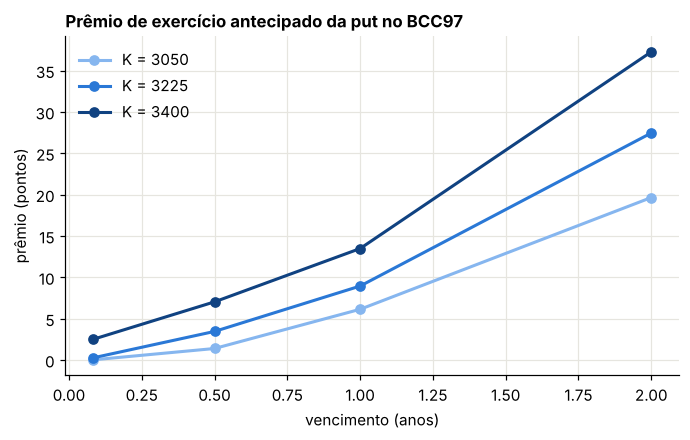

OK — a put americana nunca vale menos que a europeia (a menos do ruído)
OK — K = 3050: o prêmio cresce com o vencimento
OK — K = 3225: o prêmio cresce com o vencimento
OK — K = 3400: o prêmio cresce com o vencimento
OK — sem dividendos, a call americana não tem prêmio sobre a europeia (diferença positiva só de ruído)
OK — as diferenças negativas são pequenas: custo de exercícios por erro de regressão do LSM


In [8]:
fig, ax = plt.subplots()
for K, cor in zip(K2, RAMPA):
    d = tab4[tab4["K"] == K]
    ax.plot(d["T"], d["prêmio de exercício"], "o-", color=cor, label=f"K = {K:.0f}")
ax.set_xlabel("vencimento (anos)"); ax.set_ylabel("prêmio (pontos)")
ax.set_title("Prêmio de exercício antecipado da put no BCC97")
ax.legend(); plt.show()

ok((tab4["prêmio de exercício"] > -0.5).all(), "a put americana nunca vale menos que a europeia (a menos do ruído)")
for K in K2:
    d = tab4[tab4["K"] == K]["prêmio de exercício"].values
    ok(np.all(np.diff(d) > -0.5), f"K = {K:.0f}: o prêmio cresce com o vencimento")
dc = tab4["call americana − europeia (mesmas trajetórias)"]
ok(dc.max() < 0.6, "sem dividendos, a call americana não tem prêmio sobre a europeia (diferença positiva só de ruído)")
ok(dc.min() > -1.5, "as diferenças negativas são pequenas: custo de exercícios por erro de regressão do LSM")

**O que aprendemos.** O prêmio cresce com o vencimento e com o strike, como o livro mostra. Mas os números do livro para 3 anos (49 a 75 pontos) incluem o viés da Seção 3, que em 3 anos passa de 40 pontos. Com trajetórias corretas e a europeia como controle, o prêmio é uma diferença limpa. E a call americana, como manda a teoria sem dividendos, não tem prêmio. As pequenas diferenças negativas vêm de exercícios por engano: a regressão às vezes estima o valor de continuação abaixo do valor intrínseco, e todo exercício antecipado de uma call sem dividendos destrói valor. É o viés para baixo do LSM (Módulo 9), visível aqui porque o valor certo é conhecido.

---
## 6. Síntese

| Tema | Lição |
|---|---|
| Saltos na simulação | integram-se exatamente: $N \sim$ Poisson, soma de log-saltos normal dado $N$, compensador $-r_J\Delta t$ |
| Teste da martingal | detecta em uma linha a falta do compensador ($\approx S_0\lvert r_J\rvert T$) |
| Viés da §12.3.1 | não é do Euler: é o `v[t]` com $\rho \approx -1$, parcialmente mascarado pelo moment matching |
| Distribuição | os cumulantes da função característica conferem a simulação inteira, não só a média |
| Americanas | prêmio = americana com controle − europeia de Fourier; call sem dividendos não tem prêmio |

## 7. Erratas e notas sobre o capítulo 12

| Onde | O quê |
|---|---|
| §12.5.1, `B96_generate_paths` | `rj` é calculado e nunca usado: falta o compensador $-r_J\Delta t$ de (12.1); o índice perde $\lvert r_J\rvert$ de drift por ano |
| Eq. (12.1) e código | saltos aditivos com um único tamanho para todos os $y_t$ saltos do passo; o exato é $e^{N\mu_J + \sqrt N\delta z}$ |
| Eq. (12.1) e código | a variância do passo é `v[t]`, do fim do passo (Módulo 12); com $\rho = -0{,}999$, o drift espúrio é $-0{,}475$ por ano |
| §12.3.1 | o viés de 22 a 52 pontos atribuído ao número de passos vem do `v[t]`; o esquema exato acerta com 50 passos por ano a partir de 6 meses (só no prazo de 1 mês, com 4 passos, há viés de Euler de 1 a 2 pontos) |
| §12.3.2 | a "diferença" americana − europeia mistura prêmio e viés de simulação |
| §12.5.3, título | "American Call Options", mas o script avalia puts |
| Parâmetros do livro | $\rho = -0{,}999$, $\delta = 0$ e $\lambda = 0{,}008$ vêm da calibração degenerada do Módulo 14 |
| Scripts | Python 2 (`xrange`, `print`, `I / 2`) |

## 8. Exercícios

**Exercício 1.** Mostre que, no esquema aditivo do livro, $\mathbb{E}[S_t\,|\,S_s] = S_s\big(e^{(\bar r - r_J)\Delta t} + \lambda\Delta t\,(e^{\mu_J + \delta^2/2} - 1)\big)$ quando se usa $v_s$, e que isso difere de $S_se^{\bar r\Delta t}$ por um termo de ordem $\Delta t^2$.

<details><summary>Solução</summary>

O primeiro termo tem média $e^{(\bar r - r_J)\Delta t}$; o segundo, $\mathbb{E}[e^{\mu_J + \delta z} - 1]\,\mathbb{E}[y] = (e^{\mu_J + \delta^2/2} - 1)\lambda\Delta t = r_J\Delta t$. Logo $e^{\bar r\Delta t}e^{-r_J\Delta t} + r_J\Delta t \approx e^{\bar r\Delta t}(1 - r_J\Delta t + r_J\Delta t) + O(\Delta t^2)$. Com o compensador, a forma aditiva acerta a média em primeira ordem; sem ele, erra por $r_J\Delta t$ a cada passo, como no Laboratório 1.
</details>

**Exercício 2.** No Laboratório 2, troque apenas `olhar_frente=True` por `False`, mantendo o resto do código do livro. O viés desaparece?

<details><summary>Solução</summary>

O viés positivo desaparece. Sobra um viés **negativo**, o do compensador ausente: com $r_J \approx -0{,}3\%$ ao ano, o índice descontado fica cerca de 11 pontos abaixo de $S_0$ em 1 ano e 30 em 3 anos, e as calls de 1 ano saem 5 a 7 pontos abaixo da fórmula. A correção `bias` não o remove, porque só zera a média do choque browniano, não o drift ausente.
</details>

**Exercício 3.** Calcule por Monte Carlo o prêmio de exercício da put com $K = 3.400$ e $T = 1$ usando o simulador do livro, como no livro. Compare com o Laboratório 4.

<details><summary>Solução</summary>

Use `simular_bcc(LIVRO, ..., **LIVRO_CFG, trajetorias=True)` e o `lsm` sem controle, e subtraia a put europeia de Fourier. A diferença sai inflada pelo viés das trajetórias. Com o controle europeu nas mesmas trajetórias, boa parte do viés se cancela, e o prêmio volta para perto do valor limpo.
</details>

**Exercício 4.** Use os cumulantes do Laboratório 3 para estimar a vol. implícita no dinheiro e o skew de 1 ano pela expansão de Gram-Charlier (Backus, Foresi e Wu). Compare com as vol. implícitas de Lewis.

<details><summary>Solução</summary>

Na expansão, $\sigma_{impl}(k) \approx \sigma\big(1 - \tfrac{\gamma_1}{3!}\,d + \tfrac{\gamma_2}{4!}(d^2 - 1)\big)$, com $d$ a variável padronizada do strike, $\gamma_1$ a assimetria e $\gamma_2$ o excesso de curtose. A aproximação acerta o sinal e a ordem de grandeza do skew, mas perde precisão longe do dinheiro.
</details>

In [9]:
print(f"Módulo 15 concluído: {_checks['n']} verificações aprovadas.")

Módulo 15 concluído: 20 verificações aprovadas.
